# Лабораторная работа №3

Номер по списку: **3**, ПК: **3**, группа: **2**.

Варианты таблиц выбираются по кругу: (номер−1) % число строк + 1. Для ЛР3–4 N=ПК+группа; N не является номером по списку.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats, special
import pywt
plt.rcParams.update({'figure.figsize': (12,4), 'figure.dpi': 100,
                     'axes.grid': True, 'grid.alpha': .25})
number=3; pc=3; group=2
rng=np.random.default_rng(303)


## Параметры сигнала и фильтров
$N=ПК+2$, $M=N\bmod10$, $L=N\bmod3$.
При L=0: видеоимпульс длительностью N нс; полосовой фильтр от $1/t_и$ до $2/t_и$.
При L=2: $x(t)=[1+0.5\cos(2\pi f_mt)]\cos(2\pi f_ct)$, $f_c=10N$ МГц, $f_m=\lfloor N/10\rfloor+M$ МГц; заградительный фильтр вырезает несущую.
Порядок прототипа n=4 и подавление Чебышёва II 40 дБ приняты, поскольку методичка их не задаёт. Итоговый порядок полосовых преобразований — 8. Для АМ ширина режекции выбрана $f_m/2$, чтобы сохранить боковые полосы.
Структура: **сигнал → БПФ → идеальная маска → ОБПФ**; параллельно **сигнал → SOS Баттерворта / SOS Чебышёва II**.

N=5, M=5, L=2, частоты фильтра [48.75 51.25] МГц
Cheby2 задан по задерживанию −40 дБ; Butterworth — по уровню −3 дБ.


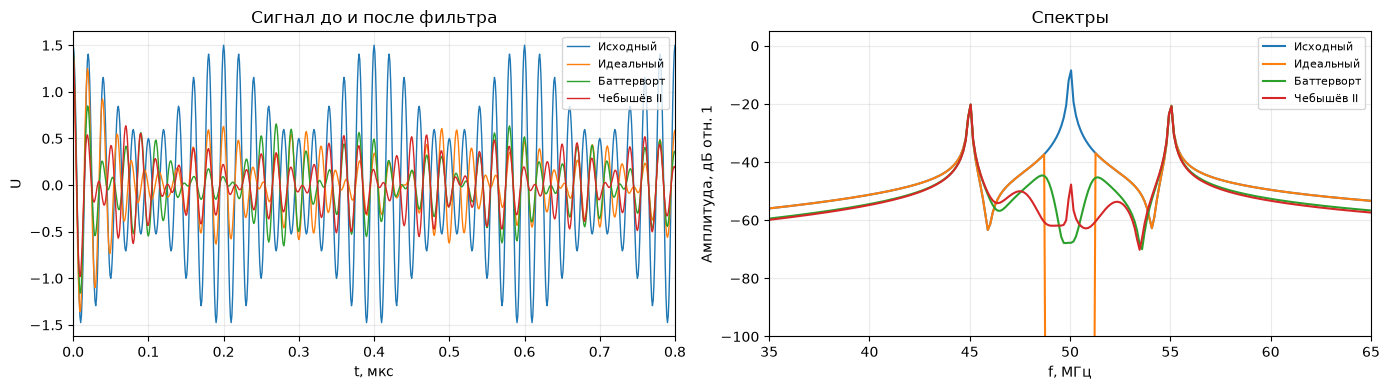

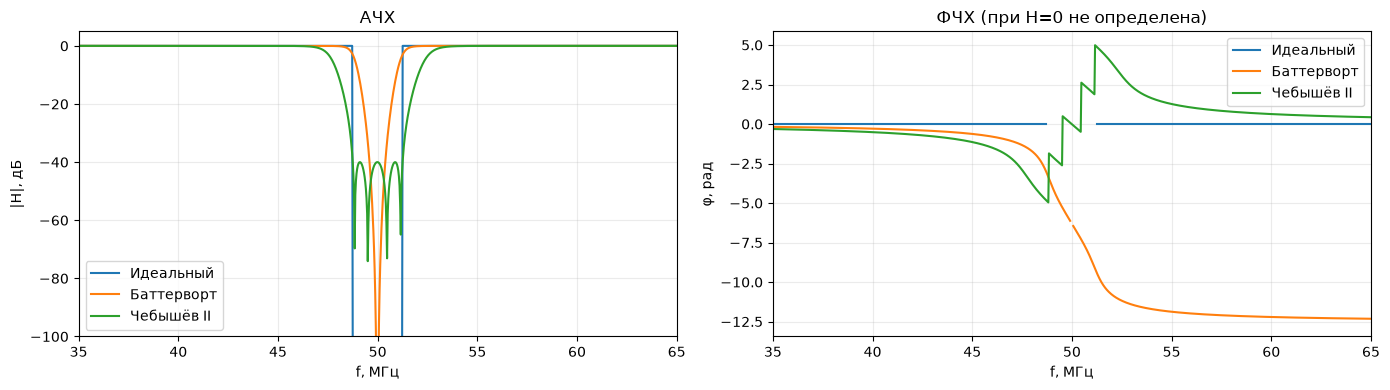

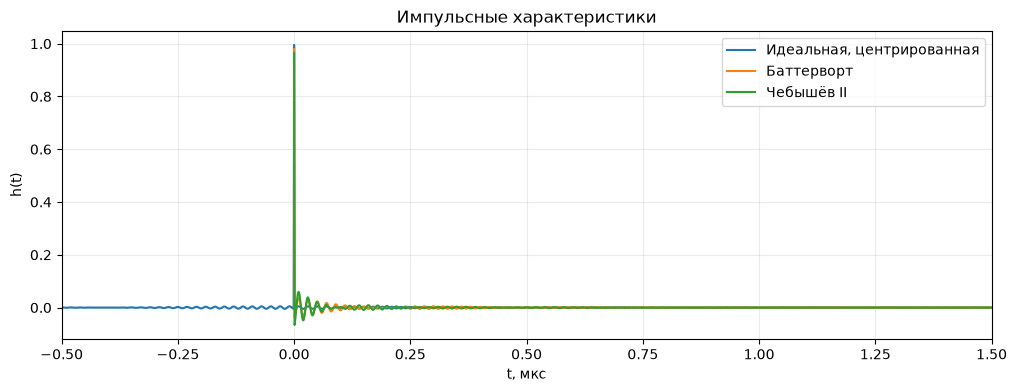

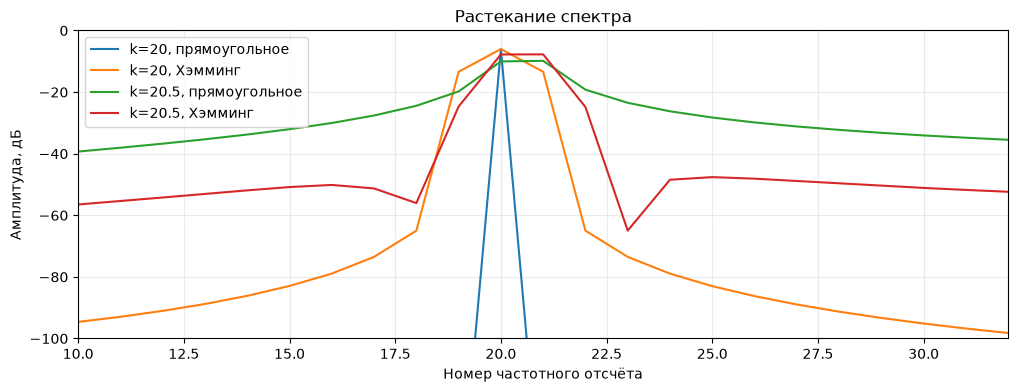

In [2]:
N=pc+group; M=N%10; L=N%3
if L==0:
    ti=N*1e-9; fs=4e9; length=8192; t=np.arange(length)/fs
    start=200e-9; x=((t>=start)&(t<start+ti)).astype(float)
    edges=np.array([1/ti,2/ti]); btype='bandpass'; plotlim=(180,300); tscale=1e9; tunit='нс'
else:
    fc=10*N*1e6; fm=(N//10+M)*1e6; fs=1e9; length=8192; t=np.arange(length)/fs
    x=(1+.5*np.cos(2*np.pi*fm*t))*np.cos(2*np.pi*fc*t)
    edges=np.array([fc-fm/4,fc+fm/4]); btype='bandstop'; plotlim=(0,.8); tscale=1e6; tunit='мкс'
f=np.fft.rfftfreq(length,1/fs)
inside=(f>=edges[0])&(f<=edges[1]); mask=inside if L==0 else ~inside
ideal=np.fft.irfft(np.fft.rfft(x)*mask,n=length)
sos_b=signal.butter(4,edges,btype=btype,fs=fs,output='sos')
# Для Cheby2 Wn — границы полосы задерживания, а не точки −3 дБ.
sos_c=signal.cheby2(4,40,edges,btype=btype,fs=fs,output='sos')
yb=signal.sosfilt(sos_b,x); yc=signal.sosfilt(sos_c,x)
print(f'N={N}, M={M}, L={L}, частоты фильтра {edges/1e6} МГц')
print('Cheby2 задан по задерживанию −40 дБ; Butterworth — по уровню −3 дБ.')
fig,axs=plt.subplots(1,2,figsize=(14,4))
for name,y in [('Исходный',x),('Идеальный',ideal),('Баттерворт',yb),('Чебышёв II',yc)]:
    axs[0].plot(t*tscale,y,label=name,lw=1)
    amp=np.abs(np.fft.rfft(y))/length
    axs[1].plot(f/1e6,20*np.log10(np.maximum(amp,1e-10)),label=name)
axs[0].set(xlabel='t, '+tunit,ylabel='U',xlim=plotlim,title='Сигнал до и после фильтра')
axs[1].set(xlabel='f, МГц',ylabel='Амплитуда, дБ отн. 1',title='Спектры',xlim=((0,500) if L==0 else (fc/1e6-3*fm/1e6,fc/1e6+3*fm/1e6)),ylim=(-100,5))
for ax in axs: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
w=np.linspace(0,fs/2,16000)
_,hb=signal.sosfreqz(sos_b,worN=w,fs=fs); _,hc=signal.sosfreqz(sos_c,worN=w,fs=fs)
passmask=(w>=edges[0])&(w<=edges[1]); hi=(passmask if L==0 else ~passmask).astype(float)
fig,axs=plt.subplots(1,2,figsize=(14,4))
for name,h in [('Идеальный',hi.astype(complex)),('Баттерворт',hb),('Чебышёв II',hc)]:
    axs[0].plot(w/1e6,20*np.log10(np.maximum(np.abs(h),1e-6)),label=name)
    ph=np.unwrap(np.angle(h)); ph[np.abs(h)<1e-5]=np.nan
    axs[1].plot(w/1e6,ph,label=name)
for ax in axs: ax.set(xlabel='f, МГц',xlim=((0,500) if L==0 else (fc/1e6-3*fm/1e6,fc/1e6+3*fm/1e6))); ax.legend()
axs[0].set(ylabel='|H|, дБ',ylim=(-100,5),title='АЧХ'); axs[1].set(ylabel='φ, рад',title='ФЧХ (при H=0 не определена)')
plt.tight_layout(); plt.show()
imp=np.zeros(length); imp[0]=1
h0=np.fft.fftshift(np.fft.irfft(mask.astype(float),n=length))
hb0=signal.sosfilt(sos_b,imp); hc0=signal.sosfilt(sos_c,imp)
fig,ax=plt.subplots()
ax.plot((np.arange(length)-length//2)/fs*tscale,h0,label='Идеальная, центрированная')
ax.plot(t*tscale,hb0,label='Баттерворт'); ax.plot(t*tscale,hc0,label='Чебышёв II')
ax.set(xlabel='t, '+tunit,ylabel='h(t)',title='Импульсные характеристики',xlim=((-80,160) if L==0 else (-.5,1.5))); ax.legend(); plt.show()
# Растекание спектра: целое и дробное число периодов, с окном и без.
n=np.arange(256); fig,ax=plt.subplots()
for k in [20,20.5]:
    for win,label in [(np.ones(256),'прямоугольное'),(np.hamming(256),'Хэмминг')]:
        a=np.abs(np.fft.rfft(np.cos(2*np.pi*k*n/256)*win))/win.sum()
        ax.plot(np.arange(len(a)),20*np.log10(np.maximum(a,1e-8)),label=f'k={k}, {label}')
ax.set(xlabel='Номер частотного отсчёта',ylabel='Амплитуда, дБ',xlim=(10,32),ylim=(-100,0),title='Растекание спектра'); ax.legend(); plt.show()

## КИХ через FFT и БИХ: включение, прохождение и выключение сигнала

Идеальная частотная маска выше имеет бесконечную двустороннюю ИХ. Для реализуемого **КИХ** задаём конечную ИХ оконным методом `firwin` и вычисляем **линейную свёртку через FFT** (`fftconvolve`, с нулевым дополнением). КИХ каузален, имеет линейную фазу и задержку $(K-1)/(2f_s)$.

Три фильтра: КИХ–FFT, БИХ Баттерворта и БИХ Чебышёва II. Начальные состояния нулевые. Вход содержит три участка: тишина, сигнал, тишина после сигнала. Для видеоимпульса сохраняется длительность по варианту. Для АМ несущая включается на конечный интервал; параметры АМ сохраняются.

Измеряем максимум выхода, отношение энергий выхода и входа, момент максимума, энергию остаточного отклика после выключения и время, после которого |y| остаётся ниже 1% максимума выхода. Последний показатель — длительность затухания по выбранному порогу, а не точное время исчезновения БИХ-отклика. БИХ теоретически затухает бесконечно. Для полосового сигнала задержка зависит от частоты; разность положений пиков не является универсальной групповой задержкой.

КИХ: 2049 коэффициентов, порядок 2048, задержка 1.024 мкс


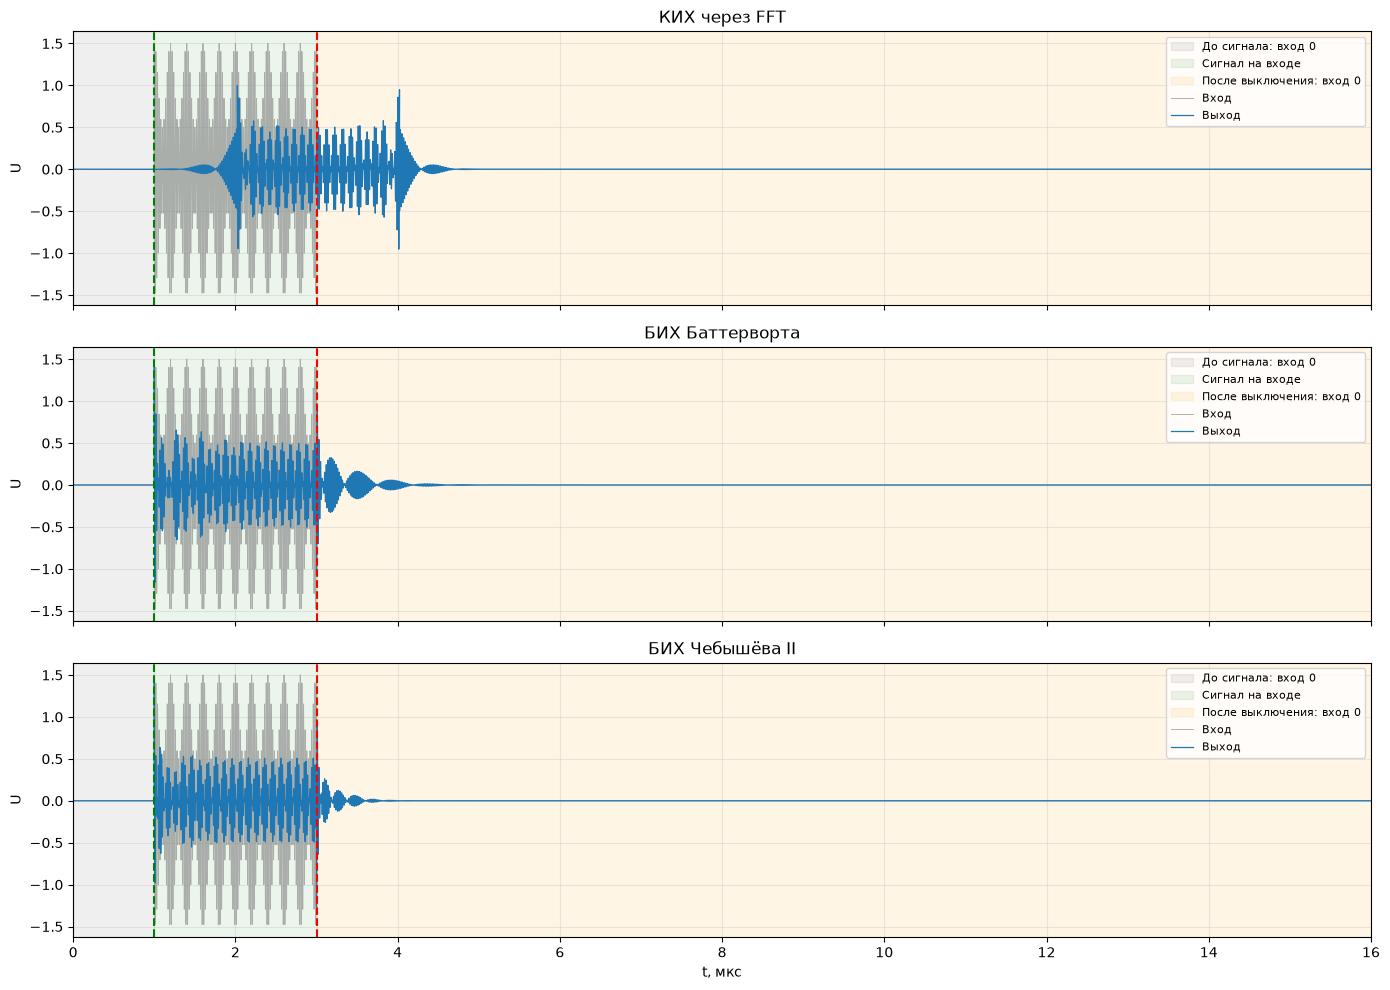

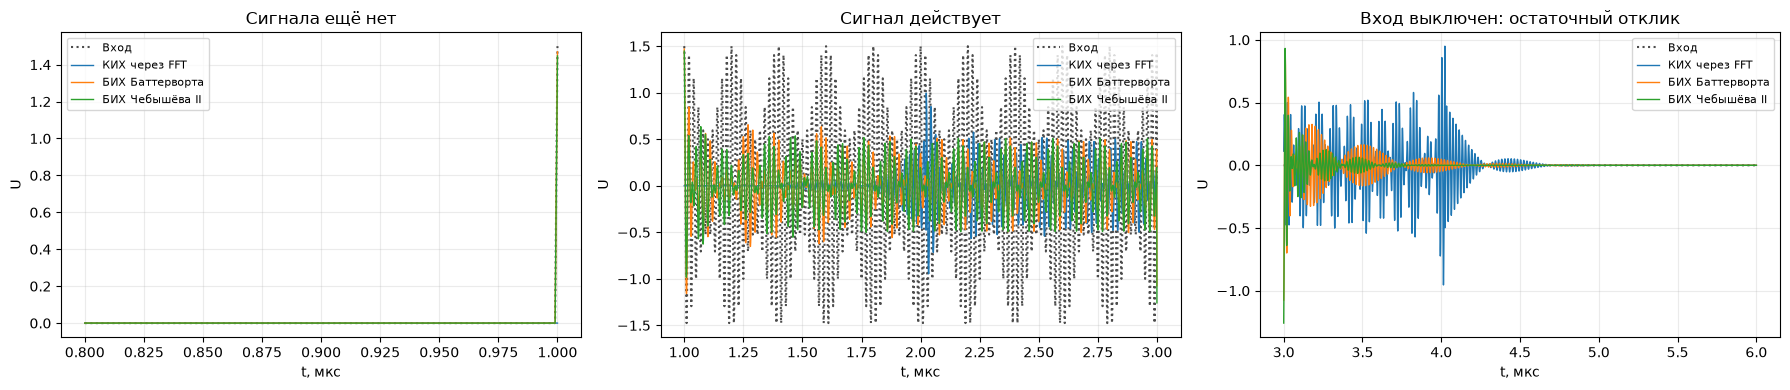

Фильтр | max|y| | Eвыход/Eвход | t максимума | хвост/Eвыход | затухание после выключения (1%)
КИХ через FFT | 0.99556 | 0.14628 | 2.024 мкс | 0.51332 | 1.646 мкс
БИХ Баттерворта | 1.46953 | 0.15050 | 1.000 мкс | 0.13159 | 1.391 мкс
БИХ Чебышёва II | 1.44716 | 0.13403 | 1.000 мкс | 0.09660 | 0.731 мкс


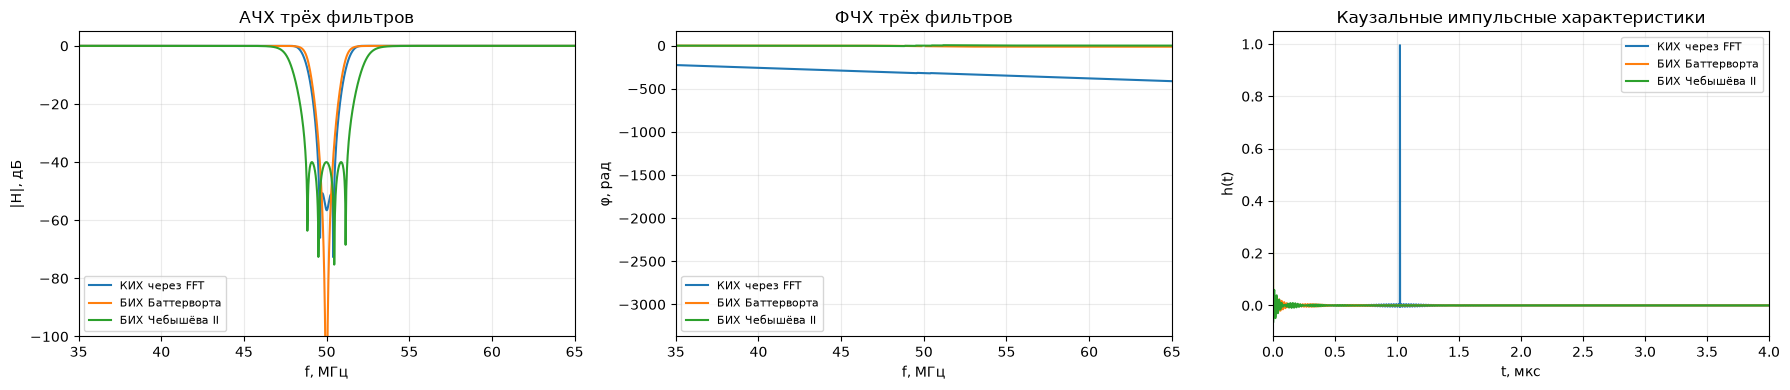

In [3]:
# Конечный КИХ: те же границы частот и тот же тип фильтра.
numtaps=1025 if L==0 else 2049
fir=signal.firwin(numtaps,edges,pass_zero=(L!=0),window='hamming',fs=fs)
fir_delay=(numtaps-1)/(2*fs)
if L==0:
    on=200e-9; duration=ti; total=2e-6
else:
    on=1e-6; duration=2e-6; total=16e-6
ns=int(round(total*fs)); tt=np.arange(ns)/fs
start_index=int(round(on*fs)); active_count=int(round(duration*fs))
end_index=start_index+active_count; off=end_index/fs
xx=np.zeros(ns)
local=np.arange(active_count)/fs
xx[start_index:end_index]=(np.ones(active_count) if L==0 else
    (1+.5*np.cos(2*np.pi*fm*local))*np.cos(2*np.pi*fc*local))
outputs={
    'КИХ через FFT':signal.fftconvolve(xx,fir,mode='full')[:ns],
    'БИХ Баттерворта':signal.sosfilt(sos_b,xx),
    'БИХ Чебышёва II':signal.sosfilt(sos_c,xx)}
assert np.allclose(outputs['КИХ через FFT'],signal.lfilter(fir,[1],xx),atol=1e-11)
assert all(np.max(np.abs(y[:start_index]))<1e-10 for y in outputs.values())
print(f'КИХ: {numtaps} коэффициентов, порядок {numtaps-1}, задержка {fir_delay*tscale:.3f} {tunit}')
# Общий вход и выход каждого фильтра: тишина → воздействие → хвост.
fig,axs=plt.subplots(3,1,figsize=(14,10),sharex=True)
for ax,(name,y) in zip(axs,outputs.items()):
    ax.axvspan(0,on*tscale,color='gray',alpha=.12,label='До сигнала: вход 0')
    ax.axvspan(on*tscale,off*tscale,color='green',alpha=.08,label='Сигнал на входе')
    ax.axvspan(off*tscale,total*tscale,color='orange',alpha=.10,label='После выключения: вход 0')
    ax.plot(tt*tscale,xx,color='gray',alpha=.6,lw=.7,label='Вход')
    ax.plot(tt*tscale,y,lw=.9,label='Выход')
    ax.axvline(on*tscale,color='green',ls='--'); ax.axvline(off*tscale,color='red',ls='--')
    ax.set(title=name,ylabel='U'); ax.legend(fontsize=8,loc='upper right')
axs[-1].set(xlabel='t, '+tunit,xlim=(0,total*tscale))
plt.tight_layout(); plt.show()
# Увеличение трёх этапов: одинаковые оси у всех фильтров.
before_width=40e-9 if L==0 else .2e-6
post_width=400e-9 if L==0 else 3e-6
ranges=[(on-before_width,on),(on,off),(off,off+post_width)]
fig,axs=plt.subplots(1,3,figsize=(18,4))
for ax,(a,b),title in zip(axs,ranges,['Сигнала ещё нет','Сигнал действует','Вход выключен: остаточный отклик']):
    sel=(tt>=a)&(tt<=b)
    ax.plot(tt[sel]*tscale,xx[sel],'k:',label='Вход',alpha=.7)
    for name,y in outputs.items(): ax.plot(tt[sel]*tscale,y[sel],label=name,lw=1)
    ax.set(title=title,xlabel='t, '+tunit,ylabel='U'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
# Количественная оценка прохождения и затухания.
Ein=np.sum(xx**2)
print('Фильтр | max|y| | Eвыход/Eвход | t максимума | хвост/Eвыход | затухание после выключения (1%)')
for name,y in outputs.items():
    peak=np.max(np.abs(y)); energy=np.sum(y**2)
    above=np.flatnonzero(np.abs(y[end_index:])>peak*.01)
    decay=((above[-1]+1)/fs) if len(above) else 0.
    settled=not len(above) or above[-1]<len(y[end_index:])-1
    decay_text=f'{decay*tscale:.3f} {tunit}' if settled else 'не затух за запись'
    print(f'{name} | {peak:.5f} | {energy/Ein:.5f} | {tt[np.argmax(np.abs(y))]*tscale:.3f} {tunit} | '
          f'{np.sum(y[end_index:]**2)/energy:.5f} | {decay_text}')
# АЧХ, ФЧХ и ИХ именно реализуемых трёх фильтров.
ff=np.linspace(0,fs/2,24000)
_,hf=signal.freqz(fir,worN=ff,fs=fs)
_,hb=signal.sosfreqz(sos_b,worN=ff,fs=fs)
_,hc=signal.sosfreqz(sos_c,worN=ff,fs=fs)
fig,axs=plt.subplots(1,3,figsize=(18,4))
for name,h in [('КИХ через FFT',hf),('БИХ Баттерворта',hb),('БИХ Чебышёва II',hc)]:
    axs[0].plot(ff/1e6,20*np.log10(np.maximum(np.abs(h),1e-8)),label=name)
    ph=np.unwrap(np.angle(h)); ph[np.abs(h)<1e-4]=np.nan
    axs[1].plot(ff/1e6,ph,label=name)
probe=np.zeros(ns); probe[0]=1
for name,h in [('КИХ через FFT',np.pad(fir,(0,ns-len(fir)))),
               ('БИХ Баттерворта',signal.sosfilt(sos_b,probe)),
               ('БИХ Чебышёва II',signal.sosfilt(sos_c,probe))]:
    axs[2].plot(tt*tscale,h,label=name)
flim=(0,300) if L==0 else (fc/1e6-3*fm/1e6,fc/1e6+3*fm/1e6)
axs[0].set(title='АЧХ трёх фильтров',xlabel='f, МГц',ylabel='|H|, дБ',xlim=flim,ylim=(-100,5))
axs[1].set(title='ФЧХ трёх фильтров',xlabel='f, МГц',ylabel='φ, рад',xlim=flim)
axs[2].set(title='Каузальные импульсные характеристики',xlabel='t, '+tunit,ylabel='h(t)',xlim=(0,(.5e-6 if L==0 else 4e-6)*tscale))
for ax in axs: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Интерпретация переходных процессов
При нулевом входе и нулевых начальных состояниях все три выхода равны нулю (малые значения FFT порядка машинной точности не являются физическим откликом). После включения возникает переходный процесс. КИХ задерживает сигнал на известное число отсчётов; его импульсный отклик конечен. БИХ накапливают состояние в обратных связях, поэтому после выключения входа остаётся затухающий колебательный хвост.

Таблица показывает, какая доля энергии прошла через фильтр и какая её часть вышла уже после выключения входа. Отношение энергий относится ко всему импульсу; оно не является коэффициентом передачи на одной частоте. У заградительного фильтра АМ несущая подавляется, но боковые полосы проходят. Конечная длительность входа дополнительно расширяет спектр и возбуждает переходные процессы на границах.

## Выводы
Идеальная маска резко ограничивает спектр, но её ИХ двусторонняя и бесконечная: отклик до воздействия означает некаузальность. БПФ реализует циклическую свёртку на конечной записи, что требует осторожности с границами. БИХ-фильтры каузальны, имеют переходную полосу, нелинейную фазу и затухающую ИХ. В начале записи наблюдается переходный процесс.
Баттерворт имеет монотонную АЧХ, Чебышёв II — пульсации в полосе задерживания и нули передачи; одинаковые численные Wn у них задают разные уровни. На частотах нулей передачи фаза не определена.
Для видеоимпульса полосовая фильтрация подавляет постоянную составляющую и формирует колебательный отклик. Для АМ заградительный фильтр подавляет несущую, оставляя две боковые полосы. Окно Хэмминга уменьшает боковые лепестки при расширении главного; дробное число периодов даёт растекание спектра.